# XAI Network Traffic Forecasting — Results & Reproduction

Notebook pendamping **Cross-Institution Reliability of Temporal Attributions in Network Traffic Forecasting**.

Dataset: CESNET-TimeSeries26, 48 institusi (32 source / 8 validation / 8 target). Notebook ini membuka hasil eksperimen yang sudah selesai; sel rerun opsional dimatikan secara default. Ekstrak **paket proyek lengkap** terlebih dahulu agar data, checkpoint, scripts, dan hasil tersedia.

Hasil primer belum konklusif: jangan mengubah hipotesis atau memilih setting baru berdasarkan hasil target yang sudah dibuka. Lihat `FULL_PROTOCOL.md` dan `RESULTS_BRIEF_ID.md`.


## 1. Environment dan lokasi proyek

Python 3.11. Instal `requirements-full.txt` pada environment yang dipakai kernel. Untuk menjalankan lewat Jupyter, tambahkan `jupyterlab` dan `ipykernel`, lalu pilih kernel environment tersebut. Instalasi paket tidak dijalankan otomatis oleh notebook.

Jika folder proyek tidak terdeteksi, isi `PROJECT_DIR` dengan lokasi folder `xai_cross_institution`. Semua angka di bawah dibaca dari hasil tersimpan, tidak ditulis ulang sebagai angka manual.


In [1]:
from pathlib import Path
import json
import sys
import subprocess
import shutil
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = None  # Contoh: "/path/to/xai_cross_institution"
candidates = ([Path(PROJECT_DIR).expanduser()] if PROJECT_DIR else [
    Path.cwd(),
    Path.cwd() / "xai_cross_institution",
    Path.cwd() / "outputs" / "xai_cross_institution",
])
ROOT = next((p.resolve() for p in candidates if (p / "results/NUMERIC_CLAIMS.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Ekstrak paket proyek lengkap, lalu isi PROJECT_DIR dengan folder xai_cross_institution.")
print("Project:", ROOT.name)
print("Python:", sys.version.split()[0])


Project: xai_cross_institution
Python: 3.11.15


## 2. Dataset, split, dan coverage

Volume dalam decimal GB; history 168 jam, endpoint 1 dan 6 jam. Tidak ada imputasi label atau konversi missing value menjadi nol. Semua institusi berada dalam satu ISP. Satu pasangan tidak memiliki common eligible origins pada 2026; jumlah pasangan efektif bukan delapan untuk semua analisis.

Sumber: [CESNET-TimeSeries26](https://doi.org/10.5281/zenodo.21945629), CC BY 4.0, Koumar, Hynek, Jeřábek, Šiška (2026).


In [2]:
split = pd.read_csv(ROOT / "INSTITUTION_SPLIT.csv")
print("Institutions per role:")
print(split.groupby("role").size().to_string())
selection = pd.read_csv(ROOT / "results/explanation_selection.csv")
print("\nExplanation selection (source + target origins):")
print(selection.groupby(["pair", "year"]).agg(
    selected=("origin", "size"), common_eligible=("common_eligible_origins", "first")
).to_string())
print("\nTarget availability:")
print(pd.read_csv(ROOT / "results/target_availability.csv").to_string(index=False))


Institutions per role:
role
source        32
target         8
validation     8

Explanation selection (source + target origins):
           selected  common_eligible
pair year                           
0    2025        32              307
     2026        32               50
1    2025        32              307
     2026        32              129
2    2025        32              206
3    2025        32              307
     2026        32              129
4    2025        32              307
     2026        32              129
5    2025        32              307
     2026        32              129
6    2025        32              307
     2026        32              129
7    2025        32              307
     2026        32              129

Target availability:
 id  year  total_hours  complete_hours  observed_values
 21  2025         2016            2016             2016
 21  2026         2014            1623             1567
233  2025         2016            2016             2

## 3. Forecasting: hasil target

MASE lebih rendah lebih baik. Angka berikut merupakan macro mean atas **15 institution-year cells yang tersedia**, setelah neural seeds dirata-ratakan. Ini bukan panel seimbang atau uji signifikansi ranking model. Frozen dan bias-calibrated adalah arm yang berbeda; calibrated memakai observasi lokal.


      model  horizon   mae_gb  rmse_gb     mase
      daily        1 0.777850 2.095774 1.083048
      daily        6 0.735423 1.973573 1.112436
    dlinear        1 0.470836 1.330169 0.682255
    dlinear        6 0.502827 1.401875 0.812195
        gru        1 0.470256 1.235198 0.684286
        gru        6 0.607109 1.528023 0.909190
persistence        1 0.501096 1.328470 0.736733
persistence        6 1.053448 2.254752 1.450587
      ridge        1 0.468365 1.330036 0.680674
      ridge        6 0.501468 1.401323 0.813232
     weekly        1 0.654098 1.709136 1.074807
     weekly        6 0.642898 1.654060 1.052985


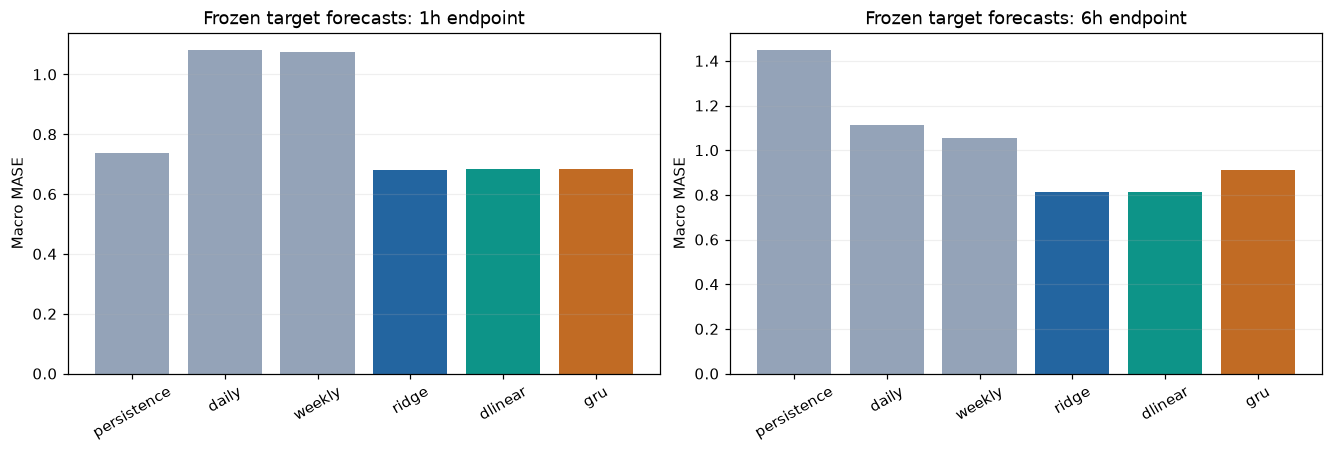

In [3]:
forecast = pd.read_csv(ROOT / "results/forecast_macro.csv")
target = forecast.query("role == 'target' and arm == 'frozen'")
print(target[["model", "horizon", "mae_gb", "rmse_gb", "mase"]].round(6).to_string(index=False))
names = ["persistence", "daily", "weekly", "ridge", "dlinear", "gru"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, horizon in zip(axes, [1, 6]):
    values = target.query("horizon == @horizon").set_index("model").reindex(names)
    ax.bar(names, values["mase"], color=["#94a3b8"] * 3 + ["#2365a0", "#0d9488", "#c16b24"])
    ax.set_title(f"Frozen target forecasts: {horizon}h endpoint")
    ax.set_ylabel("Macro MASE")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.2)
plt.show()


## 4. Endpoint primer: attribution ranking transfer

Frozen GRU, 1h, source-calendar reference, exact group Shapley. Q adalah alignment ranking dengan forecast response di bawah controlled replacement operator; bukan causal truth atau probabilitas forecast salah.

Primary aggregation: average seeds dengan skor lengkap → timestamp-paired source/target → equal year/operator cells → equal complete pairs. Interval adalah nominal paired institution/14-day-block bootstrap. Interval mencakup nol, sehingga tidak membuktikan degradasi maupun equivalence.


GRU frozen, h1, source-calendar Shapley Q, target-minus-source, paired institution/time blocks
{
  "mean": -0.018876455601195535,
  "ci_low": -0.08913930523312447,
  "ci_high": 0.05334453792169871,
  "pairs": 7,
  "bootstrap_valid": 1853,
  "reason": "nominal_paired_pair_and_14day_block_bootstrap"
}

Complete-pair operator means (equal-year weighted):
 pair      operator   source   target     delta
    0 interpolation 0.561368 0.770463  0.209095
    0      rotation 0.664420 0.670271  0.005851
    1 interpolation 0.756404 0.532647 -0.223757
    1      rotation 0.616337 0.726742  0.110405
    3 interpolation 0.641520 0.673160  0.031639
    3      rotation 0.816539 0.659943 -0.156596
    4 interpolation 0.752179 0.666123 -0.086056
    4      rotation 0.671491 0.798281  0.126790
    5 interpolation 0.715316 0.657436 -0.057880
    5      rotation 0.726439 0.549111 -0.177327
    6 interpolation 0.684282 0.536743 -0.147539
    6      rotation 0.771003 0.719059 -0.051944
    7 interpolation 0.

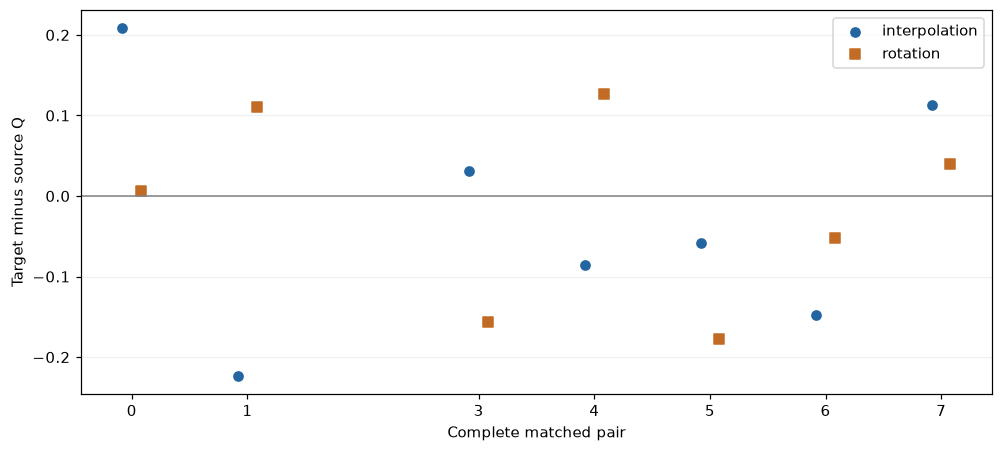

In [4]:
claims = json.loads((ROOT / "results/NUMERIC_CLAIMS.json").read_text())
print(claims["primary_definition"])
print(json.dumps(claims["primary"], indent=2))
paired = pd.read_csv(ROOT / "results/primary_complete_pair_cells.csv")
print("\nComplete-pair operator means (equal-year weighted):")
print(paired.round(6).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
for op, dx, marker, color in [("interpolation", -0.08, "o", "#2365a0"),
                              ("rotation", 0.08, "s", "#c16b24")]:
    z = paired[paired.operator == op]
    ax.scatter(z["pair"] + dx, z["delta"], marker=marker, color=color, label=op)
ax.axhline(0, color="gray", linewidth=1)
ax.set_xticks(sorted(paired["pair"].unique()))
ax.set_xlabel("Complete matched pair")
ax.set_ylabel("Target minus source Q")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.show()


## 5. Sensitivitas reference — eksploratori

Reference yang berbeda menjelaskan kontras berbeda. Interval sekunder tidak dikoreksi multiplicity dan tidak menggantikan endpoint primer. Jangan memilih hasil signifikan sebagai hipotesis utama sesudah melihat target.


In [5]:
secondary = pd.read_csv(ROOT / "results/secondary_quality_contrasts.csv")
print(secondary[["model", "horizon", "reference", "mean", "ci_low", "ci_high", "pairs"]]
      .round(6).to_string(index=False))


  model  horizon           reference      mean    ci_low   ci_high  pairs
dlinear        1 history_hour_median -0.104455 -0.209904 -0.014835      7
dlinear        1     source_calendar -0.031779 -0.148152  0.094086      7
dlinear        6 history_hour_median -0.042836 -0.131788  0.039655      7
dlinear        6     source_calendar -0.023105 -0.117237  0.075844      7
    gru        1 history_hour_median -0.068399 -0.145938 -0.003041      7
    gru        1     source_calendar -0.018876 -0.089139  0.053345      7
    gru        6 history_hour_median  0.031471 -0.041670  0.095827      7
    gru        6     source_calendar -0.044826 -0.142817  0.048940      7
  ridge        1 history_hour_median -0.084211 -0.172607 -0.012573      7
  ridge        1     source_calendar -0.035470 -0.133561  0.061891      7
  ridge        6 history_hour_median -0.054743 -0.126664  0.010885      7
  ridge        6     source_calendar -0.029092 -0.111643  0.061027      7


## 6. Audit numerik IG

IG diterima hanya jika completeness dan successive L1 refinement memenuhi toleransi yang dibekukan, maksimum 512 Gauss–Legendre nodes. Kasus gagal tetap disimpan dan tidak diberi skor IG. Lolos numerik tidak otomatis berarti ranking berguna. Kasus horizon/reference/seed berulang bukan subjek independen.


In [6]:
ig = pd.read_csv(ROOT / "results/ig_numerical_summary.csv")
ig_model = ig.groupby("model")[["cases", "accepted"]].sum()
ig_model["failed"] = ig_model["cases"] - ig_model["accepted"]
print(ig_model.to_string())
print(f"\nFailed: {int(ig_model.failed.sum())}/{int(ig_model.cases.sum())} "
      f"({100 * ig_model.failed.sum() / ig_model.cases.sum():.2f}%)")
validation = json.loads((ROOT / "results/FINAL_VALIDATION.json").read_text())
print("\nSaved independent audit:", validation["status"])
print(json.dumps(validation["checks"], indent=2))


         cases  accepted  failed
model                           
dlinear   1440      1335     105
gru       1440      1365      75
ridge      480       450      30

Failed: 210/3360 (6.25%)

Saved independent audit: pass
{
  "FULL_PREFIT_HASHES": true,
  "FULL_PREEVALUATION_HASHES": true,
  "48_data_hashes": true,
  "model_hashes": true,
  "disjoint_membership": true,
  "forecast_metric_recalculation": true,
  "checkpoint_prediction_and_truth_requeries": true,
  "permutation_shapley_oracle": true,
  "ranking_quality_requeries": true,
  "primary_point_independent": true,
  "failed_ig_never_scored": true
}


## 7. Opsional: audit ulang hasil tersimpan

Aktifkan flag untuk menghitung ulang semua forecast metrics dan memeriksa hash serta representative checkpoint/attribution queries. Tidak melatih model. Script memperbarui `results/FINAL_VALIDATION.json` pada folder proyek yang dipilih; simpan paket asli jika memerlukan salinan immutable. Torch dan dependensi penuh diperlukan.


In [7]:
RUN_AUDIT = False
if RUN_AUDIT:
    subprocess.run([sys.executable, str(ROOT / "src/validate_full_results.py")], cwd=ROOT, check=True)
else:
    print("Audit rerun disabled; saved audit shown above.")


Audit rerun disabled; saved audit shown above.


## 8. Opsional: training dan evaluasi ulang pada salinan baru

Default **False**. Saat diaktifkan, sel membuat salinan proyek di folder `work/xai_reruns/` di sebelah folder proyek. Hasil original tetap dipertahankan. Training memakai split/protokol yang sama; ini reproduksi, bukan test holdout baru karena outcome sudah pernah dibuka.

`RUN_TRAINING=True` melatih ulang Ridge, DLinear dan GRU. `RUN_EVALUATION=True` menjalankan forecast, attribution, analysis, reporting assets dan final audit. Untuk mengulang evaluasi checkpoint yang disediakan, aktifkan hanya evaluasi. Untuk reproduksi lengkap, aktifkan keduanya. Runtime dan identitas numerik dapat berbeda antar sistem. Tidak ada download data, cloud compute atau biaya otomatis.


In [8]:
RUN_TRAINING = False
RUN_EVALUATION = False
if RUN_TRAINING or RUN_EVALUATION:
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    rerun_base = (ROOT.parent / "work" / "xai_reruns").resolve()
    if rerun_base == ROOT or ROOT in rerun_base.parents:
        raise ValueError("Buka notebook dari parent folder atau pilih rerun_base di luar ROOT agar copy tidak rekursif.")
    rerun_base.mkdir(parents=True, exist_ok=True)
    RUN_ROOT = rerun_base / stamp
    shutil.copytree(ROOT, RUN_ROOT, ignore=shutil.ignore_patterns("__pycache__", "*.aux", "*.log", "*.out"))
    scripts = (["train_full.py"] if RUN_TRAINING else [])
    if RUN_EVALUATION:
        scripts += ["evaluate_forecasts.py", "evaluate_attributions.py", "analyze_full.py",
                    "build_reporting_assets.py", "validate_full_results.py"]
    for script in scripts:
        print("Running:", script, flush=True)
        subprocess.run([sys.executable, str(RUN_ROOT / "src" / script)], cwd=RUN_ROOT, check=True)
    print("Rerun saved:", RUN_ROOT)
else:
    print("Training/evaluation rerun disabled. Original experiment files unchanged.")


Training/evaluation rerun disabled. Original experiment files unchanged.


## 9. Paper dan slide

- [Paper PDF](paper/paper.pdf) dan [LaTeX](paper/paper.tex): anonymous draft, 5 halaman, 18 referensi.
- [PPT editable](presentation/XAI_Research_Results_v2.pptx): opening; research gap/goal; pipeline; hasil.
- [Ringkasan Indonesia](RESULTS_BRIEF_ID.md), [literature positioning](LITERATURE_AND_GAP.md), dan [protocol](FULL_PROTOCOL.md).

Belum disubmit. Penyesuaian target konferensi, authorship, afiliasi dan disclosure tetap diperlukan. Hasil hanya dari satu ISP, tujuh pasangan primer efektif, dan dua controlled operators; generalisasi lintas ISP belum diuji.
